In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("No GPU detected. Check the Colab runtime settings.")


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4
VRAM: 14.56 GB


In [ ]:
# Installing Dataset Libraries

%pip -q install -U datasets pyarrow pillow

In [ ]:
# Load and inspect ADS504 Dataset (Source: HuggingFace)

from datasets import load_dataset

DATASET_ID = "tkbarb10/ADS504-Image-Arrays"

dataset = load_dataset(DATASET_ID)

print(dataset)
print("\nDataset splits:")
for split_name, split_data in dataset.items():
    print(f"{split_name}: {len(split_data):,} rows")

print("\nTraining features:")
print(dataset["train"].features)

print("\nFirst example:")
example = dataset["train"][0]
for key, value in example.items():
    if hasattr(value, "shape"):
        print(f"{key}: shape={value.shape}, dtype={value.dtype}")
    elif isinstance(value, (bytes, bytearray)):
        print(f"{key}: byte data, {len(value):,} bytes")
    else:
        print(f"{key}: {value}")


README.md:   0%|          | 0.00/2.11k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  417MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

...

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11998 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1500 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1499 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_name'],
        num_rows: 11998
    })
    test: Dataset({
        features: ['image', 'label', 'image_name'],
        num_rows: 1500
    })
    validation: Dataset({
        features: ['image', 'label', 'image_name'],
        num_rows: 1499
    })
})

Dataset splits:
train: 11,998 rows
test: 1,500 rows
validation: 1,499 rows

Training features:
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['ai_generated', 'human_created']), 'image_name': Value('string')}

First example:
image: <PIL.PngImagePlugin.PngImageFile image mode=RGB size=224x224 at 0x7B20461FE900>
label: 0
image_name: 00000


CLASS DISTRIBUTION
train      | AI-generated: 5,973 | Human-created: 6,025
test       | AI-generated:   755 | Human-created:   745
validation | AI-generated:   755 | Human-created:   744

FILENAME AUDIT
train: 0 duplicate filenames within split
test: 0 duplicate filenames within split
validation: 0 duplicate filenames within split
Filenames appearing across multiple splits: 1500

IMAGE AUDIT
train: mode=RGB, size=(224, 224), format=PNG
test: mode=RGB, size=(224, 224), format=PNG
validation: mode=RGB, size=(224, 224), format=PNG


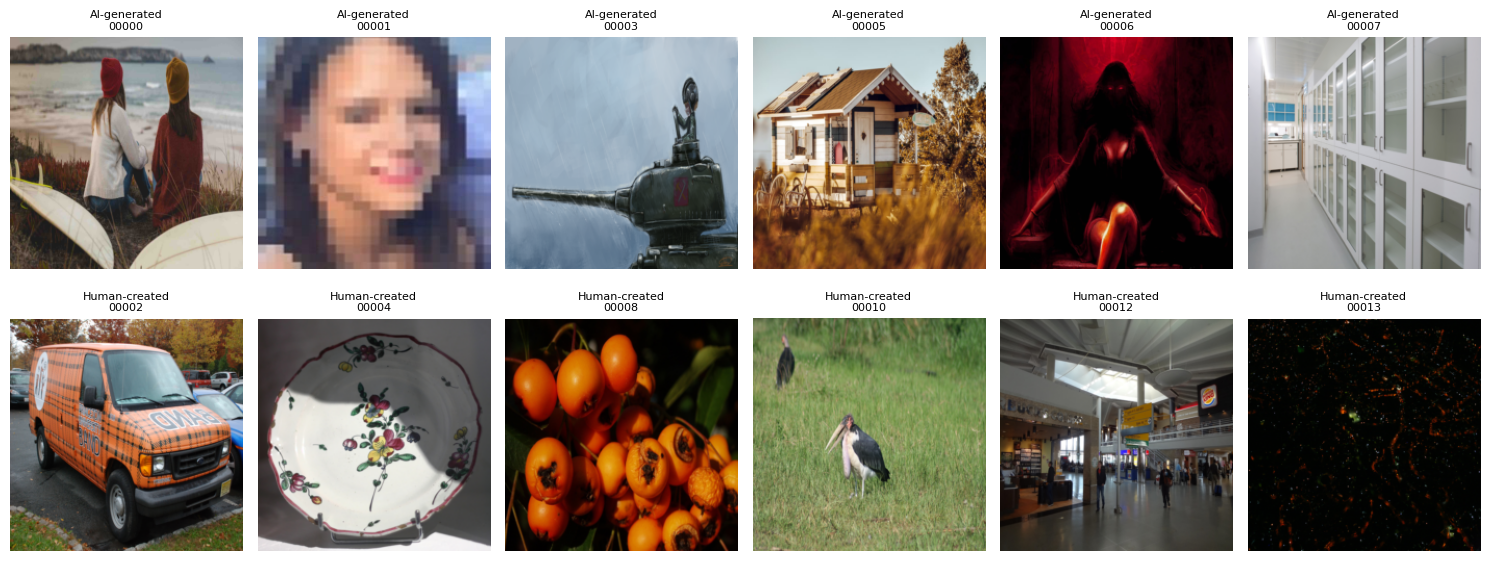


PIXEL STATISTICS (sample of up to 300 images per class)
AI-generated: mean RGB=[0.502 0.46  0.428], average pixel std RGB=[0.22  0.211 0.213]
Human-created: mean RGB=[0.479 0.447 0.401], average pixel std RGB=[0.218 0.212 0.214]


In [ ]:
# Dataset quality audit

from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# 1. Check class balance in every split
print("CLASS DISTRIBUTION")
for split_name, split_data in dataset.items():
    counts = Counter(split_data["label"])
    print(
        f"{split_name:10} | "
        f"AI-generated: {counts.get(0, 0):5,} | "
        f"Human-created: {counts.get(1, 0):5,}"
    )

# 2. Check duplicate filenames within and across splits
print("\nFILENAME AUDIT")
all_names = {}

for split_name, split_data in dataset.items():
    names = split_data["image_name"]
    duplicate_count = len(names) - len(set(names))
    print(f"{split_name}: {duplicate_count} duplicate filenames within split")

    for name in names:
        all_names.setdefault(name, []).append(split_name)

cross_split_names = {
    name: splits
    for name, splits in all_names.items()
    if len(set(splits)) > 1
}
print("Filenames appearing across multiple splits:", len(cross_split_names))

# 3. Inspect dimensions, modes, and pixel statistics
print("\nIMAGE AUDIT")
for split_name in dataset:
    sample = dataset[split_name][0]["image"]
    print(
        f"{split_name}: mode={sample.mode}, "
        f"size={sample.size}, format={sample.format}"
    )

# 4. Display balanced samples from both classes
train_data = dataset["train"]
ai_indices = [i for i, y in enumerate(train_data["label"]) if y == 0][:6]
human_indices = [i for i, y in enumerate(train_data["label"]) if y == 1][:6]

fig, axes = plt.subplots(2, 6, figsize=(15, 6))

for row, (indices, class_name) in enumerate([
    (ai_indices, "AI-generated"),
    (human_indices, "Human-created")
]):
    for col, idx in enumerate(indices):
        image = train_data[idx]["image"]
        axes[row, col].imshow(image)
        axes[row, col].set_title(
            f"{class_name}\n{train_data[idx]['image_name']}",
            fontsize=8
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

# 5. Compare average brightness and channel variation by class
print("\nPIXEL STATISTICS (sample of up to 300 images per class)")
for label, class_name in [(0, "AI-generated"), (1, "Human-created")]:
    indices = [
        i for i, y in enumerate(train_data["label"]) if y == label
    ][:300]

    means, stds = [], []
    for idx in indices:
        arr = np.asarray(train_data[idx]["image"], dtype=np.float32) / 255.0
        means.append(arr.mean(axis=(0, 1)))
        stds.append(arr.std(axis=(0, 1)))

    print(
        f"{class_name}: "
        f"mean RGB={np.mean(means, axis=0).round(3)}, "
        f"average pixel std RGB={np.mean(stds, axis=0).round(3)}"
    )


In [ ]:
# Step 5: Investigate possible data leakage


import hashlib
from collections import defaultdict
import numpy as np

# Build a fingerprint from each image's decoded RGB pixels.
# Identical pixel fingerprints indicate exact image duplicates.
fingerprints = {}
name_records = defaultdict(list)
hash_records = defaultdict(list)

for split_name, split_data in dataset.items():
    for i, example in enumerate(split_data):
        name = example["image_name"]
        label = int(example["label"])

        rgb = np.asarray(example["image"].convert("RGB"))
        image_hash = hashlib.sha256(rgb.tobytes()).hexdigest()

        record = {
            "split": split_name,
            "index": i,
            "name": name,
            "label": label,
            "hash": image_hash,
        }

        name_records[name].append(record)
        hash_records[image_hash].append(record)

# 1. Filename reuse across splits
reused_names = {
    name: records
    for name, records in name_records.items()
    if len({r["split"] for r in records}) > 1
}

# 2. Exact image duplicates across splits
cross_split_duplicates = {
    image_hash: records
    for image_hash, records in hash_records.items()
    if len({r["split"] for r in records}) > 1
}

# 3. Exact duplicates with conflicting labels
conflicting_duplicate_groups = {
    image_hash: records
    for image_hash, records in cross_split_duplicates.items()
    if len({r["label"] for r in records}) > 1
}

# 4. Same filename but different images
reused_names_different_images = 0
reused_names_different_labels = 0

for records in reused_names.values():
    hashes = {r["hash"] for r in records}
    labels = {r["label"] for r in records}

    if len(hashes) > 1:
        reused_names_different_images += 1
    if len(labels) > 1:
        reused_names_different_labels += 1

print("CROSS-SPLIT LEAKAGE CHECK")
print("Unique filenames appearing across splits:", len(reused_names))
print("Reused filenames referring to different images:", reused_names_different_images)
print("Reused filenames with conflicting labels:", reused_names_different_labels)
print("Exact image duplicates across splits:", len(cross_split_duplicates))
print("Exact duplicate groups with conflicting labels:", len(conflicting_duplicate_groups))

# Show a few examples to understand the naming convention
print("\nEXAMPLES OF REUSED FILENAMES")
for name, records in list(reused_names.items())[:5]:
    print(
        name,
        [
            (r["split"], r["index"], r["label"], r["hash"][:12])
            for r in records
        ]
    )


CROSS-SPLIT LEAKAGE CHECK
Unique filenames appearing across splits: 1500
Reused filenames referring to different images: 1500
Reused filenames with conflicting labels: 1107
Exact image duplicates across splits: 0
Exact duplicate groups with conflicting labels: 0

EXAMPLES OF REUSED FILENAMES
00000 [('train', 0, 0, '7f3db5808902'), ('test', 0, 1, 'd58abad82d0d'), ('validation', 0, 1, 'c23b5a6b7348')]
00001 [('train', 1, 0, '2c60bfa4803c'), ('test', 1, 0, '269c25d81533'), ('validation', 1, 0, 'd28495f72134')]
00002 [('train', 2, 1, 'f9b4d4622fe8'), ('test', 2, 1, '158aa490bbe3'), ('validation', 2, 1, '22c8dc211019')]
00003 [('train', 3, 0, 'aa9e48b46e20'), ('test', 3, 0, 'a4c9d59e11d7'), ('validation', 3, 0, '5fc93588f2e8')]
00004 [('train', 4, 1, '9dc57041b0f9'), ('test', 4, 1, '5615256aed0c'), ('validation', 4, 0, 'c1b0b2aa77ba')]


In [ ]:
# Step 6 — Verify dataset provenance


from huggingface_hub import hf_hub_download

readme_path = hf_hub_download(
    repo_id="tkbarb10/ADS504-Image-Arrays",
    filename="README.md",
    repo_type="dataset"
)

with open(readme_path, "r", encoding="utf-8") as file:
    readme = file.read()

print(readme)


---
license: mit
dataset_info:
  features:
  - name: image
    dtype: image
  - name: label
    dtype:
      class_label:
        names:
          '0': ai_generated
          '1': human_created
  - name: image_name
    dtype: string
  splits:
  - name: train
    num_bytes: 831331860
    num_examples: 11998
  - name: test
    num_bytes: 102610854
    num_examples: 1500
  - name: validation
    num_bytes: 101540782
    num_examples: 1499
  download_size: 1035437916
  dataset_size: 1035483496
configs:
- config_name: default
  data_files:
  - split: train
    path: data/train-*
  - split: test
    path: data/test-*
  - split: validation
    path: data/validation-*
task_categories:
- image-classification
language:
- en
tags:
- images
- ai
pretty_name: Skynet Detection
size_categories:
- 10K<n<100K
---

# Description

Roughly 15k images evenly split between AI generated and human generated for the purpose of training models to detect AI generated content.
Images have been converted to numpy 

In [ ]:
# Step 7 — Inspect the upstream dataset metadata


from huggingface_hub import HfApi

api = HfApi()

repo_id = "Hemg/AI-Generated-vs-Real-Images-Datasets"

try:
    info = api.dataset_info(repo_id)
    print("Repository:", info.id)
    print("Last modified:", info.last_modified)
    print("\nFiles:")
    for item in api.list_repo_tree(
        repo_id,
        repo_type="dataset",
        recursive=True
    ):
        if hasattr(item, "size"):
            print(f"{item.path} | {item.size} bytes")
        else:
            print(item.path)
except Exception as error:
    print("Metadata inspection failed:", repr(error))


Repository: Hemg/AI-Generated-vs-Real-Images-Datasets
Last modified: 2024-03-10 11:54:30+00:00

Files:
AiArtData
AiArtData/AiArtData
RealArt
RealArt/RealArt
data
.gitattributes | 2307 bytes
AiArtData/AiArtData/-how-important-people-from-the-past-really-looked-11-Pics-5ffd5c0f4d77f__880.jpg | 97136 bytes
AiArtData/AiArtData/-s-fluffy-fur-and-round-features-immediately-melted-the-viewer-s-heart-photo.jpg | 329446 bytes
AiArtData/AiArtData/-using-generative-ai-technology-landscape-pattern-abstract-concept-269270897.jpg | 267045 bytes
AiArtData/AiArtData/-yellow-kimono-with-a-golden-crown-and-a-very-detailed-Barn-owl-copy-800x800.jpg | 89671 bytes
AiArtData/AiArtData/.amazonaws.com2Fpublic2Fimages2Ff89de3bb-279b-42c9-9822-a653fb5b21e6_600x480.png | 52677 bytes
AiArtData/AiArtData/0002_AI-in-animal-classification.png | 199760 bytes
AiArtData/AiArtData/00urban_biodiversity_landscape_architecture_14ed209d-45ca-4c57-b995-4d1552813cc1.jpg | 585336 bytes
AiArtData/AiArtData/03a3gbCKfH8dDJnjhHLuH

In [ ]:
# Step 8 — Summarize the upstream repository

from collections import defaultdict

repo_id = "Hemg/AI-Generated-vs-Real-Images-Datasets"

files = [
    item
    for item in api.list_repo_tree(
        repo_id,
        repo_type="dataset",
        recursive=True
    )
    if hasattr(item, "size") and item.size is not None
]

folders = defaultdict(lambda: {"count": 0, "bytes": 0})

for item in files:
    parts = item.path.split("/")
    folder = "/".join(parts[:-1]) if len(parts) > 1 else "(root)"
    folders[folder]["count"] += 1
    folders[folder]["bytes"] += item.size

print("Total files:", len(files))
print("Total size (GB):", round(sum(f["bytes"] for f in folders.values()) / 1e9, 2))
print("\nLargest directories:")

for folder, stats in sorted(
    folders.items(),
    key=lambda x: x[1]["bytes"],
    reverse=True
)[:25]:
    print(
        f"{folder:60} "
        f"{stats['count']:6,} files | "
        f"{stats['bytes'] / 1e9:8.2f} GB"
    )

print("\nExample file paths:")
for item in files[:20]:
    print(item.path)


Total files: 983
Total size (GB): 1.88

Largest directories:
data                                                              6 files |     1.37 GB
AiArtData/AiArtData                                             539 files |     0.29 GB
RealArt/RealArt                                                 436 files |     0.22 GB
(root)                                                            2 files |     0.00 GB

Example file paths:
.gitattributes
AiArtData/AiArtData/-how-important-people-from-the-past-really-looked-11-Pics-5ffd5c0f4d77f__880.jpg
AiArtData/AiArtData/-s-fluffy-fur-and-round-features-immediately-melted-the-viewer-s-heart-photo.jpg
AiArtData/AiArtData/-using-generative-ai-technology-landscape-pattern-abstract-concept-269270897.jpg
AiArtData/AiArtData/-yellow-kimono-with-a-golden-crown-and-a-very-detailed-Barn-owl-copy-800x800.jpg
AiArtData/AiArtData/.amazonaws.com2Fpublic2Fimages2Ff89de3bb-279b-42c9-9822-a653fb5b21e6_600x480.png
AiArtData/AiArtData/0002_AI-in-animal-classifi

In [ ]:
# Step 9 — Finalize the data pipeline configuration


from collections import Counter
from torch.utils.data import DataLoader
from torchvision import transforms
import torch

# Central experiment configuration
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 2
NUM_WORKERS = 2

LABEL_NAMES = {
    0: "AI-generated",
    1: "Human-created",
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ImageNet normalization for pretrained CNNs
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

print("Device:", DEVICE)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Training labels:", Counter(dataset["train"]["label"]))
print("Validation labels:", Counter(dataset["validation"]["label"]))
print("Test labels:", Counter(dataset["test"]["label"]))


Device: cuda
Image size: 224
Batch size: 32
Training labels: Counter({1: 6025, 0: 5973})
Validation labels: Counter({0: 755, 1: 744})
Test labels: Counter({0: 755, 1: 745})


In [ ]:
# Step 10 — Build the dataset wrapper and DataLoaders


from torch.utils.data import Dataset, DataLoader
from PIL import Image

class AIGeneratedImageDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.data = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        example = self.data[idx]

        image = example["image"].convert("RGB")
        label = int(example["label"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label


train_dataset = AIGeneratedImageDataset(
    dataset["train"], train_transform
)
val_dataset = AIGeneratedImageDataset(
    dataset["validation"], eval_transform
)
test_dataset = AIGeneratedImageDataset(
    dataset["test"], eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

# Verify one training batch
images, labels = next(iter(train_loader))

print("Training batch shape:", images.shape)
print("Training labels shape:", labels.shape)
print("Batch label counts:", {
    LABEL_NAMES[int(k)]: int(v)
    for k, v in zip(*torch.unique(labels, return_counts=True))
})
print("Image tensor dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batch shape: torch.Size([32, 3, 224, 224])
Training labels shape: torch.Size([32])
Batch label counts: {'AI-generated': 12, 'Human-created': 20}
Image tensor dtype: torch.float32
Label dtype: torch.int64
Training batches: 375
Validation batches: 47
Test batches: 47


In [ ]:
# Step 11 — Build the reusable model factory


import torch.nn as nn
from torchvision import models

def build_model(model_name, num_classes=NUM_CLASSES, pretrained=True):
    """
    Create a pretrained image classifier with a binary-classification head.
    Supported: efficientnet_b0, resnet50, convnext_tiny
    """
    if model_name == "efficientnet_b0":
        weights = (
            models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        )
        model = models.efficientnet_b0(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)

    elif model_name == "resnet50":
        weights = (
            models.ResNet50_Weights.DEFAULT if pretrained else None
        )
        model = models.resnet50(weights=weights)
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)

    elif model_name == "convnext_tiny":
        weights = (
            models.ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None
        )
        model = models.convnext_tiny(weights=weights)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Linear(in_features, num_classes)

    else:
        raise ValueError(f"Unsupported model: {model_name}")

    return model


# Verify architecture heads without loading all three onto the GPU.
for name in ["efficientnet_b0", "resnet50", "convnext_tiny"]:
    model = build_model(name, pretrained=False)
    print(f"{name}: output classes = {model(torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)).shape[-1]}")
    del model

if torch.cuda.is_available():
    torch.cuda.empty_cache()


efficientnet_b0: output classes = 2
resnet50: output classes = 2
convnext_tiny: output classes = 2


In [ ]:
# Step 12 — Confirm the models work with pretrained weights


model = build_model("efficientnet_b0", pretrained=True).to(DEVICE)

# Check one forward pass
model.eval()
with torch.no_grad():
    sample_images, _ = next(iter(val_loader))
    sample_images = sample_images[:2].to(DEVICE)
    sample_outputs = model(sample_images)

print("Model:", "EfficientNet-B0")
print("Output shape:", sample_outputs.shape)
print("Device:", next(model.parameters()).device)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 146MB/s]


Model: EfficientNet-B0
Output shape: torch.Size([2, 2])
Device: cuda:0
Trainable parameters: 4010110


In [ ]:
# Step 13 — Create the shared training and evaluation functions


import copy
import time
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
)
from torchvision import models

def freeze_backbone(model, model_name):
    """Freeze feature-extraction layers; leave the classifier trainable."""
    for param in model.parameters():
        param.requires_grad = False

    if model_name == "efficientnet_b0":
        for param in model.classifier.parameters():
            param.requires_grad = True
    elif model_name == "resnet50":
        for param in model.fc.parameters():
            param.requires_grad = True
    elif model_name == "convnext_tiny":
        for param in model.classifier.parameters():
            param.requires_grad = True
    else:
        raise ValueError(f"Unsupported model: {model_name}")

    return model


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        all_preds.extend(outputs.argmax(dim=1).detach().cpu().tolist())
        all_labels.extend(labels.detach().cpu().tolist())

    return {
        "loss": running_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_preds),
    }


@torch.no_grad()
def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_labels, all_probs, all_preds = [], [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)
        probs = torch.softmax(outputs, dim=1)

        running_loss += loss.item() * labels.size(0)
        all_labels.extend(labels.cpu().tolist())
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(outputs.argmax(dim=1).cpu().tolist())

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_preds)
    probabilities = np.asarray(all_probs)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1],
        average="macro",
        zero_division=0,
    )

    return {
        "loss": running_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
        "roc_auc": roc_auc_score(y_true, probabilities[:, 1]),
        "labels": y_true,
        "predictions": y_pred,
        "probabilities": probabilities,
    }


def fit_model(
    model,
    train_loader,
    val_loader,
    model_name,
    epochs=3,
    learning_rate=1e-3,
    patience=2,
):
    """Train a frozen-backbone baseline and retain its best validation checkpoint."""
    model = freeze_backbone(model, model_name).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=learning_rate,
        weight_decay=1e-4,
    )

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, epochs + 1):
        start = time.time()

        train_metrics = train_one_epoch(
            model, train_loader, optimizer, criterion, DEVICE
        )
        val_metrics = evaluate_model(
            model, val_loader, criterion, DEVICE
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "val_auc": val_metrics["roc_auc"],
        })

        print(
            f"{model_name} | Epoch {epoch}/{epochs} | "
            f"train loss {train_metrics['loss']:.4f} | "
            f"train acc {train_metrics['accuracy']:.4f} | "
            f"val loss {val_metrics['loss']:.4f} | "
            f"val acc {val_metrics['accuracy']:.4f} | "
            f"val balanced acc {val_metrics['balanced_accuracy']:.4f} | "
            f"{time.time() - start:.1f}s"
        )

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print("Early stopping: validation loss did not improve.")
            break

    model.load_state_dict(best_state)

    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
    }


In [ ]:
# Step 14 — Train the EfficientNet-B0 baseline


# Train the first baseline
baseline_result = fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="efficientnet_b0",
    epochs=3,
    learning_rate=1e-3,
    patience=2,
)

baseline_model = baseline_result["model"]

print("\nBest epoch:", baseline_result["best_epoch"])
print("Best validation loss:", round(baseline_result["best_val_loss"], 4))


efficientnet_b0 | Epoch 1/3 | train loss 0.5386 | train acc 0.7315 | val loss 0.4847 | val acc 0.7859 | val balanced acc 0.7856 | 47.9s
efficientnet_b0 | Epoch 2/3 | train loss 0.4939 | train acc 0.7692 | val loss 0.4816 | val acc 0.7905 | val balanced acc 0.7908 | 41.5s
efficientnet_b0 | Epoch 3/3 | train loss 0.4893 | train acc 0.7734 | val loss 0.4752 | val acc 0.7972 | val balanced acc 0.7975 | 40.4s

Best epoch: 3
Best validation loss: 0.4752


In [ ]:
# Step 16 — Fine-tune EfficientNet-B0
# (1. making the training function support fine-tuning explicitly)

def fit_finetune_model(
    model,
    train_loader,
    val_loader,
    model_name,
    epochs=3,
    learning_rate=1e-4,
    patience=2,
):
    # Freeze the whole network first
    for param in model.parameters():
        param.requires_grad = False

    # Unfreeze the final feature blocks and classifier
    if model_name == "efficientnet_b0":
        for block in list(model.features.children())[-2:]:
            for param in block.parameters():
                param.requires_grad = True
        for param in model.classifier.parameters():
            param.requires_grad = True

    elif model_name == "resnet50":
        for param in model.layer4.parameters():
            param.requires_grad = True
        for param in model.fc.parameters():
            param.requires_grad = True

    elif model_name == "convnext_tiny":
        for param in model.features[-1].parameters():
            param.requires_grad = True
        for param in model.classifier.parameters():
            param.requires_grad = True

    else:
        raise ValueError(f"Unsupported model: {model_name}")

    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=learning_rate,
        weight_decay=1e-4,
    )

    best_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    stale_epochs = 0
    history = []

    for epoch in range(1, epochs + 1):
        start = time.time()

        train_metrics = train_one_epoch(
            model, train_loader, optimizer, criterion, DEVICE
        )
        val_metrics = evaluate_model(
            model, val_loader, criterion, DEVICE
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "val_auc": val_metrics["roc_auc"],
        })

        print(
            f"{model_name} fine-tune | Epoch {epoch}/{epochs} | "
            f"train acc {train_metrics['accuracy']:.4f} | "
            f"val acc {val_metrics['accuracy']:.4f} | "
            f"val balanced acc {val_metrics['balanced_accuracy']:.4f} | "
            f"val AUC {val_metrics['roc_auc']:.4f} | "
            f"{time.time() - start:.1f}s"
        )

        if val_metrics["loss"] < best_loss:
            best_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            stale_epochs = 0
        else:
            stale_epochs += 1

        if stale_epochs >= patience:
            print("Early stopping.")
            break

    model.load_state_dict(best_state)

    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_loss": best_loss,
    }


In [ ]:
# (2. Fine Tuning)

fine_tune_result = fit_finetune_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="efficientnet_b0",
    epochs=3,
    learning_rate=1e-4,
    patience=2,
)

baseline_model = fine_tune_result["model"]


efficientnet_b0 fine-tune | Epoch 1/3 | train acc 0.7944 | val acc 0.8139 | val balanced acc 0.8140 | val AUC 0.8992 | 42.6s
efficientnet_b0 fine-tune | Epoch 2/3 | train acc 0.8306 | val acc 0.8306 | val balanced acc 0.8304 | val AUC 0.9078 | 42.0s
efficientnet_b0 fine-tune | Epoch 3/3 | train acc 0.8567 | val acc 0.8352 | val balanced acc 0.8354 | val AUC 0.9125 | 49.5s


In [ ]:
# Step 18 — Save the EfficientNet checkpoint


import os
import torch

OUTPUT_DIR = "/content/ai_image_detection"
os.makedirs(OUTPUT_DIR, exist_ok=True)

efficientnet_path = os.path.join(
    OUTPUT_DIR, "efficientnet_b0_ads504.pth"
)

torch.save(
    {
        "model_name": "efficientnet_b0",
        "model_state_dict": baseline_model.state_dict(),
        "num_classes": NUM_CLASSES,
        "image_size": IMAGE_SIZE,
        "label_names": LABEL_NAMES,
        "best_epoch": fine_tune_result["best_epoch"],
        "best_val_loss": fine_tune_result["best_val_loss"],
        "history": fine_tune_result["history"],
    },
    efficientnet_path,
)

print("Saved checkpoint:", efficientnet_path)
print("File size (MB):", round(os.path.getsize(efficientnet_path) / 1e6, 2))


Saved checkpoint: /content/ai_image_detection/efficientnet_b0_ads504.pth
File size (MB): 16.35


In [ ]:
# Step 19 — Start ResNet-50


# Stage 1: ResNet-50 frozen-backbone baseline
resnet_model = build_model("resnet50", pretrained=True).to(DEVICE)

resnet_baseline_result = fit_model(
    model=resnet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="resnet50",
    epochs=3,
    learning_rate=1e-3,
    patience=2,
)

resnet_model = resnet_baseline_result["model"]

print("\nResNet-50 best baseline epoch:",
      resnet_baseline_result["best_epoch"])


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 106MB/s]


resnet50 | Epoch 1/3 | train loss 0.4903 | train acc 0.7727 | val loss 0.4252 | val acc 0.8145 | val balanced acc 0.8147 | 58.0s
resnet50 | Epoch 2/3 | train loss 0.4180 | train acc 0.8187 | val loss 0.4061 | val acc 0.8225 | val balanced acc 0.8224 | 54.2s
resnet50 | Epoch 3/3 | train loss 0.3930 | train acc 0.8306 | val loss 0.4022 | val acc 0.8252 | val balanced acc 0.8250 | 54.4s

ResNet-50 best baseline epoch: 3


In [ ]:
# Step 21 — Fine-tune ResNet-50


resnet_finetune_result = fit_finetune_model(
    model=resnet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="resnet50",
    epochs=3,
    learning_rate=1e-4,
    patience=2,
)

resnet_model = resnet_finetune_result["model"]

print("\nResNet-50 fine-tuning best epoch:",
      resnet_finetune_result["best_epoch"])
print("Best validation loss:",
      round(resnet_finetune_result["best_val_loss"], 4))


resnet50 fine-tune | Epoch 1/3 | train acc 0.8470 | val acc 0.8626 | val balanced acc 0.8626 | val AUC 0.9376 | 73.1s
resnet50 fine-tune | Epoch 2/3 | train acc 0.9416 | val acc 0.8519 | val balanced acc 0.8518 | val AUC 0.9354 | 69.1s
resnet50 fine-tune | Epoch 3/3 | train acc 0.9745 | val acc 0.8672 | val balanced acc 0.8675 | val AUC 0.9385 | 67.9s
Early stopping.

ResNet-50 fine-tuning best epoch: 1
Best validation loss: 0.32


In [ ]:
# Step 23 — Save the ResNet-50 checkpoint

resnet_path = os.path.join(
    OUTPUT_DIR, "resnet50_ads504.pth"
)

torch.save(
    {
        "model_name": "resnet50",
        "model_state_dict": resnet_model.state_dict(),
        "num_classes": NUM_CLASSES,
        "image_size": IMAGE_SIZE,
        "label_names": LABEL_NAMES,
        "best_epoch": resnet_finetune_result["best_epoch"],
        "best_val_loss": resnet_finetune_result["best_val_loss"],
        "history": resnet_finetune_result["history"],
    },
    resnet_path,
)

print("Saved checkpoint:", resnet_path)
print("File size (MB):", round(os.path.getsize(resnet_path) / 1e6, 2))


Saved checkpoint: /content/ai_image_detection/resnet50_ads504.pth
File size (MB): 94.37


In [ ]:
# Step 24 — Start ConvNeXt-Tiny


convnext_model = build_model("convnext_tiny", pretrained=True).to(DEVICE)

convnext_baseline_result = fit_model(
    model=convnext_model,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="convnext_tiny",
    epochs=3,
    learning_rate=1e-3,
    patience=2,
)

convnext_model = convnext_baseline_result["model"]

print("\nConvNeXt-Tiny baseline best epoch:",
      convnext_baseline_result["best_epoch"])
print("Best validation loss:",
      round(convnext_baseline_result["best_val_loss"], 4))


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:01<00:00, 72.9MB/s]


convnext_tiny | Epoch 1/3 | train loss 0.4663 | train acc 0.7843 | val loss 0.4054 | val acc 0.8272 | val balanced acc 0.8273 | 70.4s
convnext_tiny | Epoch 2/3 | train loss 0.4035 | train acc 0.8240 | val loss 0.3977 | val acc 0.8286 | val balanced acc 0.8286 | 67.4s
convnext_tiny | Epoch 3/3 | train loss 0.3891 | train acc 0.8344 | val loss 0.3941 | val acc 0.8366 | val balanced acc 0.8363 | 66.4s

ConvNeXt-Tiny baseline best epoch: 3
Best validation loss: 0.3941


In [ ]:
# Step 26 — Fine-tune ConvNeXt-Tiny


convnext_finetune_result = fit_finetune_model(
    model=convnext_model,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="convnext_tiny",
    epochs=3,
    learning_rate=1e-4,
    patience=2,
)

convnext_model = convnext_finetune_result["model"]

print("\nConvNeXt-Tiny fine-tuning best epoch:",
      convnext_finetune_result["best_epoch"])
print("Best validation loss:",
      round(convnext_finetune_result["best_val_loss"], 4))


convnext_tiny fine-tune | Epoch 1/3 | train acc 0.8516 | val acc 0.8626 | val balanced acc 0.8622 | val AUC 0.9383 | 86.3s
convnext_tiny fine-tune | Epoch 2/3 | train acc 0.9363 | val acc 0.8672 | val balanced acc 0.8670 | val AUC 0.9421 | 83.8s
convnext_tiny fine-tune | Epoch 3/3 | train acc 0.9760 | val acc 0.8666 | val balanced acc 0.8664 | val AUC 0.9437 | 83.6s
Early stopping.

ConvNeXt-Tiny fine-tuning best epoch: 1
Best validation loss: 0.3243


In [ ]:
# Step 28 — Save ConvNeXt-Tiny


convnext_path = os.path.join(
    OUTPUT_DIR, "convnext_tiny_ads504.pth"
)

torch.save(
    {
        "model_name": "convnext_tiny",
        "model_state_dict": convnext_model.state_dict(),
        "num_classes": NUM_CLASSES,
        "image_size": IMAGE_SIZE,
        "label_names": LABEL_NAMES,
        "best_epoch": convnext_finetune_result["best_epoch"],
        "best_val_loss": convnext_finetune_result["best_val_loss"],
        "history": convnext_finetune_result["history"],
    },
    convnext_path,
)

print("Saved checkpoint:", convnext_path)
print("File size (MB):", round(os.path.getsize(convnext_path) / 1e6, 2))


Saved checkpoint: /content/ai_image_detection/convnext_tiny_ads504.pth
File size (MB): 111.36


In [ ]:
# Step 29 — Build the final validation comparison

criterion = nn.CrossEntropyLoss()

models_to_compare = {
    "EfficientNet-B0": baseline_model,
    "ResNet-50": resnet_model,
    "ConvNeXt-Tiny": convnext_model,
}

validation_results = {}

for name, trained_model in models_to_compare.items():
    metrics = evaluate_model(
        trained_model,
        val_loader,
        criterion,
        DEVICE,
    )
    validation_results[name] = metrics

    print(
        f"{name}: "
        f"accuracy={metrics['accuracy']:.4f}, "
        f"balanced_accuracy={metrics['balanced_accuracy']:.4f}, "
        f"macro_F1={metrics['macro_f1']:.4f}, "
        f"ROC_AUC={metrics['roc_auc']:.4f}, "
        f"loss={metrics['loss']:.4f}"
    )


EfficientNet-B0: accuracy=0.8352, balanced_accuracy=0.8354, macro_F1=0.8352, ROC_AUC=0.9125, loss=0.3802
ResNet-50: accuracy=0.8626, balanced_accuracy=0.8626, macro_F1=0.8626, ROC_AUC=0.9376, loss=0.3200
ConvNeXt-Tiny: accuracy=0.8626, balanced_accuracy=0.8622, macro_F1=0.8622, ROC_AUC=0.9383, loss=0.3243


In [ ]:
# Step 31 — Evaluate the untouched test set

# Final in-dataset test evaluation.
# Run once after choosing the primary model based on validation results.

final_test_results = {}

for name, trained_model in models_to_compare.items():
    metrics = evaluate_model(
        trained_model,
        test_loader,
        criterion,
        DEVICE,
    )
    final_test_results[name] = metrics

    print(f"\n{name}")
    print(f"Accuracy:          {metrics['accuracy']:.4f}")
    print(f"Balanced accuracy: {metrics['balanced_accuracy']:.4f}")
    print(f"Macro F1:          {metrics['macro_f1']:.4f}")
    print(f"ROC-AUC:           {metrics['roc_auc']:.4f}")



EfficientNet-B0
Accuracy:          0.8247
Balanced accuracy: 0.8249
Macro F1:          0.8246
ROC-AUC:           0.9104

ResNet-50
Accuracy:          0.8493
Balanced accuracy: 0.8495
Macro F1:          0.8493
ROC-AUC:           0.9323

ConvNeXt-Tiny
Accuracy:          0.8587
Balanced accuracy: 0.8585
Macro F1:          0.8585
ROC-AUC:           0.9317


In [ ]:
# Step 33 — Test robustness to image quality


from PIL import Image
from io import BytesIO
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class ImageQualityDataset(Dataset):
    def __init__(self, hf_dataset, condition):
        self.data = hf_dataset
        self.condition = condition
        self.to_tensor = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
            ),
        ])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        example = self.data[idx]
        image = example["image"].convert("RGB")

        if self.condition == "jpeg75":
            buffer = BytesIO()
            image.save(buffer, format="JPEG", quality=75)
            buffer.seek(0)
            image = Image.open(buffer).convert("RGB")

        elif self.condition == "jpeg50":
            buffer = BytesIO()
            image.save(buffer, format="JPEG", quality=50)
            buffer.seek(0)
            image = Image.open(buffer).convert("RGB")

        elif self.condition == "downscale":
            image = image.resize((56, 56), Image.Resampling.LANCZOS)

        elif self.condition != "original":
            raise ValueError(f"Unknown condition: {self.condition}")

        return self.to_tensor(image), int(example["label"])


quality_conditions = [
    "original",
    "jpeg75",
    "jpeg50",
    "downscale",
]

quality_results = {}

for condition in quality_conditions:
    quality_dataset = ImageQualityDataset(
        dataset["test"], condition
    )
    quality_loader = DataLoader(
        quality_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    metrics = evaluate_model(
        convnext_model,
        quality_loader,
        criterion,
        DEVICE,
    )

    quality_results[condition] = metrics

    print(
        f"{condition:10} | "
        f"accuracy={metrics['accuracy']:.4f} | "
        f"balanced_accuracy={metrics['balanced_accuracy']:.4f} | "
        f"AUC={metrics['roc_auc']:.4f}"
    )


original   | accuracy=0.8587 | balanced_accuracy=0.8585 | AUC=0.9317
jpeg75     | accuracy=0.8060 | balanced_accuracy=0.8055 | AUC=0.8912
jpeg50     | accuracy=0.7853 | balanced_accuracy=0.7848 | AUC=0.8751
downscale  | accuracy=0.6980 | balanced_accuracy=0.6965 | AUC=0.8123


In [ ]:
# Step 36 — Choose a manageable external benchmark


from huggingface_hub import HfApi

external_repo = "OwensLab/CommunityForensics-Small"
api = HfApi()

try:
    external_info = api.dataset_info(external_repo)
    print("Dataset:", external_info.id)
    print("\nFiles and sizes:")

    files = list(api.list_repo_tree(
        external_repo,
        repo_type="dataset",
        recursive=True
    ))

    total_bytes = 0
    for item in files:
        if hasattr(item, "size") and item.size is not None:
            total_bytes += item.size
            print(f"{item.path} | {item.size / 1e6:.1f} MB")

    print(f"\nTotal listed file size: {total_bytes / 1e9:.2f} GB")

except Exception as error:
    print("Could not inspect external dataset:", repr(error))


Dataset: OwensLab/CommunityForensics-Small

Files and sizes:
.gitattributes | 0.0 MB
README.md | 0.0 MB
data/HFCF_small_0.parquet | 1231.9 MB
data/HFCF_small_1.parquet | 1205.0 MB
data/HFCF_small_10.parquet | 1144.0 MB
data/HFCF_small_100.parquet | 4104.6 MB
data/HFCF_small_101.parquet | 4077.6 MB
data/HFCF_small_102.parquet | 4105.2 MB
data/HFCF_small_103.parquet | 4099.7 MB
data/HFCF_small_104.parquet | 4098.6 MB
data/HFCF_small_105.parquet | 4098.2 MB
data/HFCF_small_106.parquet | 4087.5 MB
data/HFCF_small_107.parquet | 4093.0 MB
data/HFCF_small_108.parquet | 4084.2 MB
data/HFCF_small_109.parquet | 4095.9 MB
data/HFCF_small_11.parquet | 1154.3 MB
data/HFCF_small_110.parquet | 4085.2 MB
data/HFCF_small_111.parquet | 4088.9 MB
data/HFCF_small_112.parquet | 4093.3 MB
data/HFCF_small_113.parquet | 4094.1 MB
data/HFCF_small_114.parquet | 3532.6 MB
data/HFCF_small_115.parquet | 2629.3 MB
data/HFCF_small_116.parquet | 1127.7 MB
data/HFCF_small_117.parquet | 152.3 MB
data/HFCF_small_118.par

In [ ]:
# Step 37 — Error analysis of ConvNeXt-Tiny

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# Use the existing final test results
results = final_test_results["ConvNeXt-Tiny"]

y_true = np.asarray(results["labels"])
y_pred = np.asarray(results["predictions"])

print("Classification Report:\n")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["AI-generated", "Human-created"],
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:")
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
print(pd.DataFrame(
    cm,
    index=["Actual AI-generated", "Actual Human-created"],
    columns=["Predicted AI-generated", "Predicted Human-created"]
))

# Identify misclassified examples
misclassified_indices = np.flatnonzero(y_true != y_pred)

print(f"\nTotal test images: {len(y_true)}")
print(f"Misclassified images: {len(misclassified_indices)}")
print(f"Error rate: {len(misclassified_indices) / len(y_true):.2%}")

# Show a few examples with their true and predicted labels
error_examples = pd.DataFrame({
    "test_index": misclassified_indices[:15],
    "actual_label": [LABEL_NAMES[int(y_true[i])] for i in misclassified_indices[:15]],
    "predicted_label": [LABEL_NAMES[int(y_pred[i])] for i in misclassified_indices[:15]],
})

display(error_examples)

Classification Report:

               precision    recall  f1-score   support

 AI-generated     0.8415    0.8861    0.8632       755
Human-created     0.8780    0.8309    0.8538       745

     accuracy                         0.8587      1500
    macro avg     0.8598    0.8585    0.8585      1500
 weighted avg     0.8596    0.8587    0.8585      1500

Confusion Matrix:
                      Predicted AI-generated  Predicted Human-created
Actual AI-generated                      669                       86
Actual Human-created                     126                      619

Total test images: 1500
Misclassified images: 212
Error rate: 14.13%


,test_index,actual_label,predicted_label
0,3,AI-generated,Human-created
1,6,Human-created,AI-generated
2,11,AI-generated,Human-created
3,15,Human-created,AI-generated
4,17,AI-generated,Human-created
5,19,AI-generated,Human-created
6,20,Human-created,AI-generated
7,23,Human-created,AI-generated
8,41,Human-created,AI-generated
9,45,Human-created,AI-generated


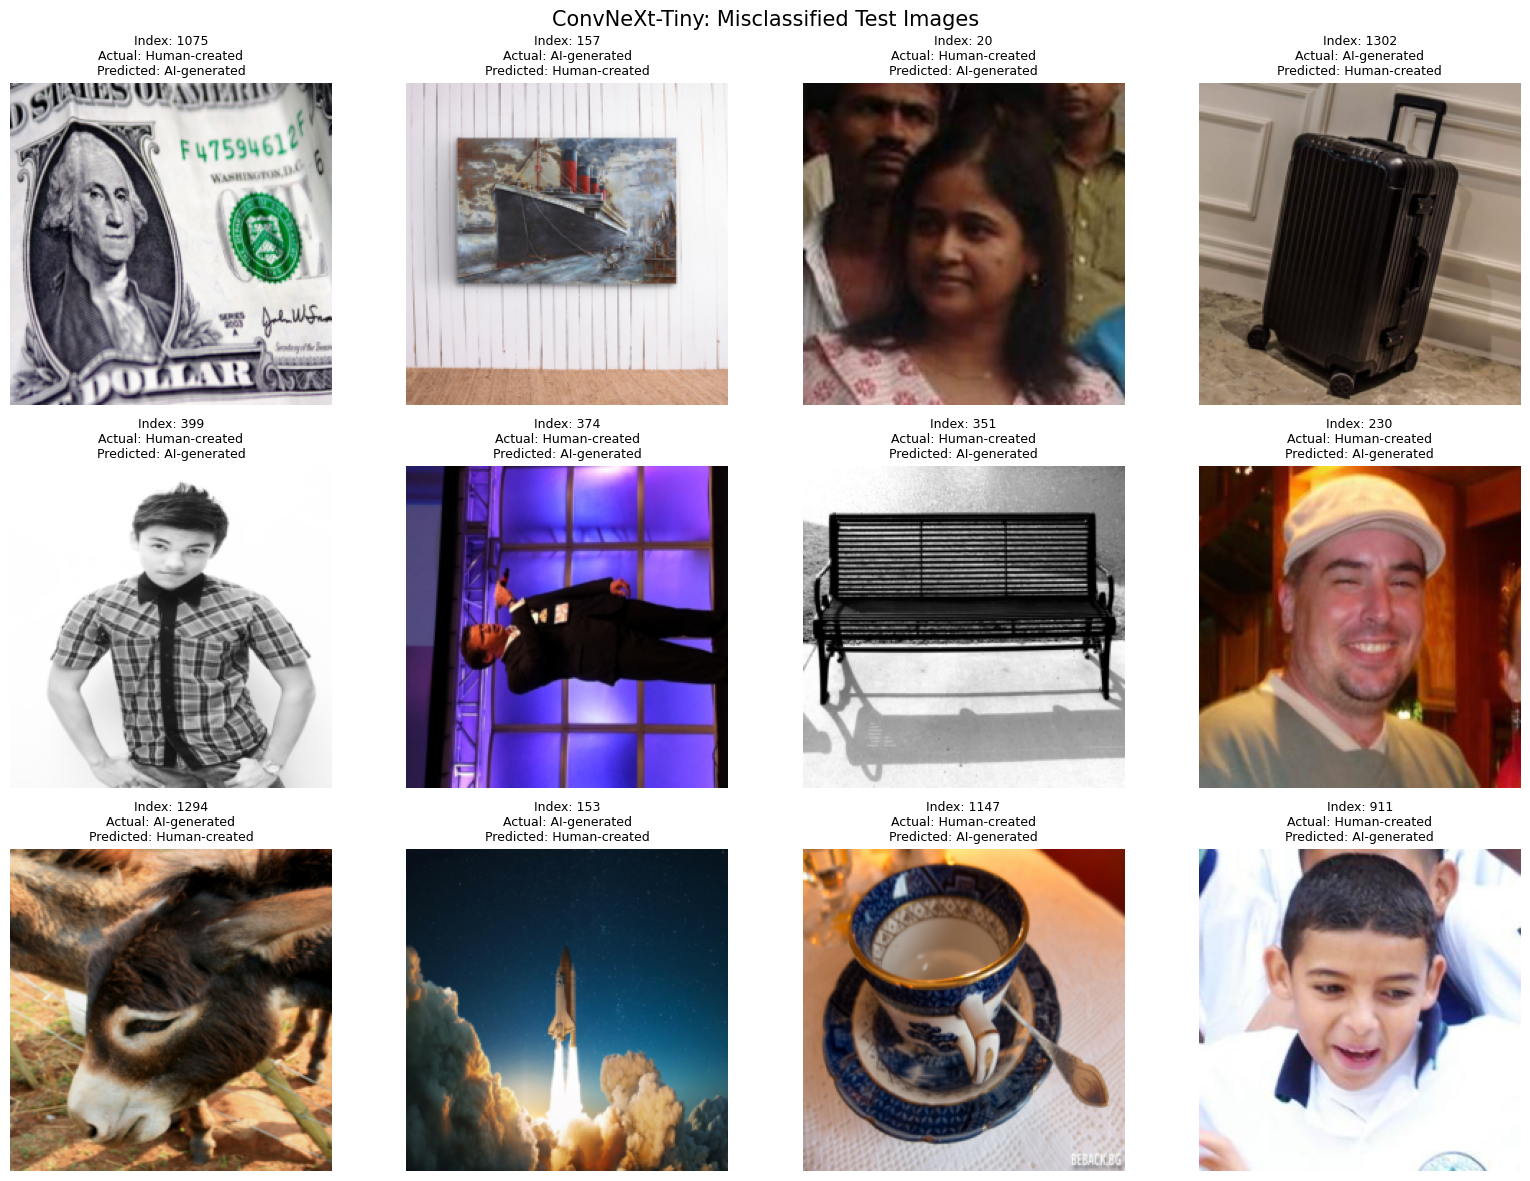

In [ ]:
# Step 38 — Visually inspect the mistakes

import matplotlib.pyplot as plt
import numpy as np
import random

# Reproduce the same misclassified indices from Step 37
results = final_test_results["ConvNeXt-Tiny"]

y_true = np.asarray(results["labels"])
y_pred = np.asarray(results["predictions"])
misclassified_indices = np.flatnonzero(y_true != y_pred)

# Select up to 12 mistakes for visual inspection
random.seed(SEED)
selected_indices = random.sample(
    list(misclassified_indices),
    min(12, len(misclassified_indices))
)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, idx in zip(axes, selected_indices):
    image = dataset["test"][int(idx)]["image"].convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"Index: {idx}\n"
        f"Actual: {LABEL_NAMES[int(y_true[idx])]}\n"
        f"Predicted: {LABEL_NAMES[int(y_pred[idx])]}",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[len(selected_indices):]:
    ax.axis("off")

plt.suptitle("ConvNeXt-Tiny: Misclassified Test Images", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# Step 39 — Grad-CAM interpretability

# Step 39A: Verify the trained ConvNeXt model and inspect its layers

convnext_model = models_to_compare["ConvNeXt-Tiny"]
convnext_model = convnext_model.to(DEVICE)
convnext_model.eval()

print("Model:", type(convnext_model).__name__)
print("\nFinal feature blocks:")
print(convnext_model.features[-1])

print("\nClassifier:")
print(convnext_model.classifier)

print("\nDevice:", next(convnext_model.parameters()).device)

Model: ConvNeXt

Final feature blocks:
Sequential(
  (0): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.08823529411764706, mode=row)
  )
  (1): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.094117

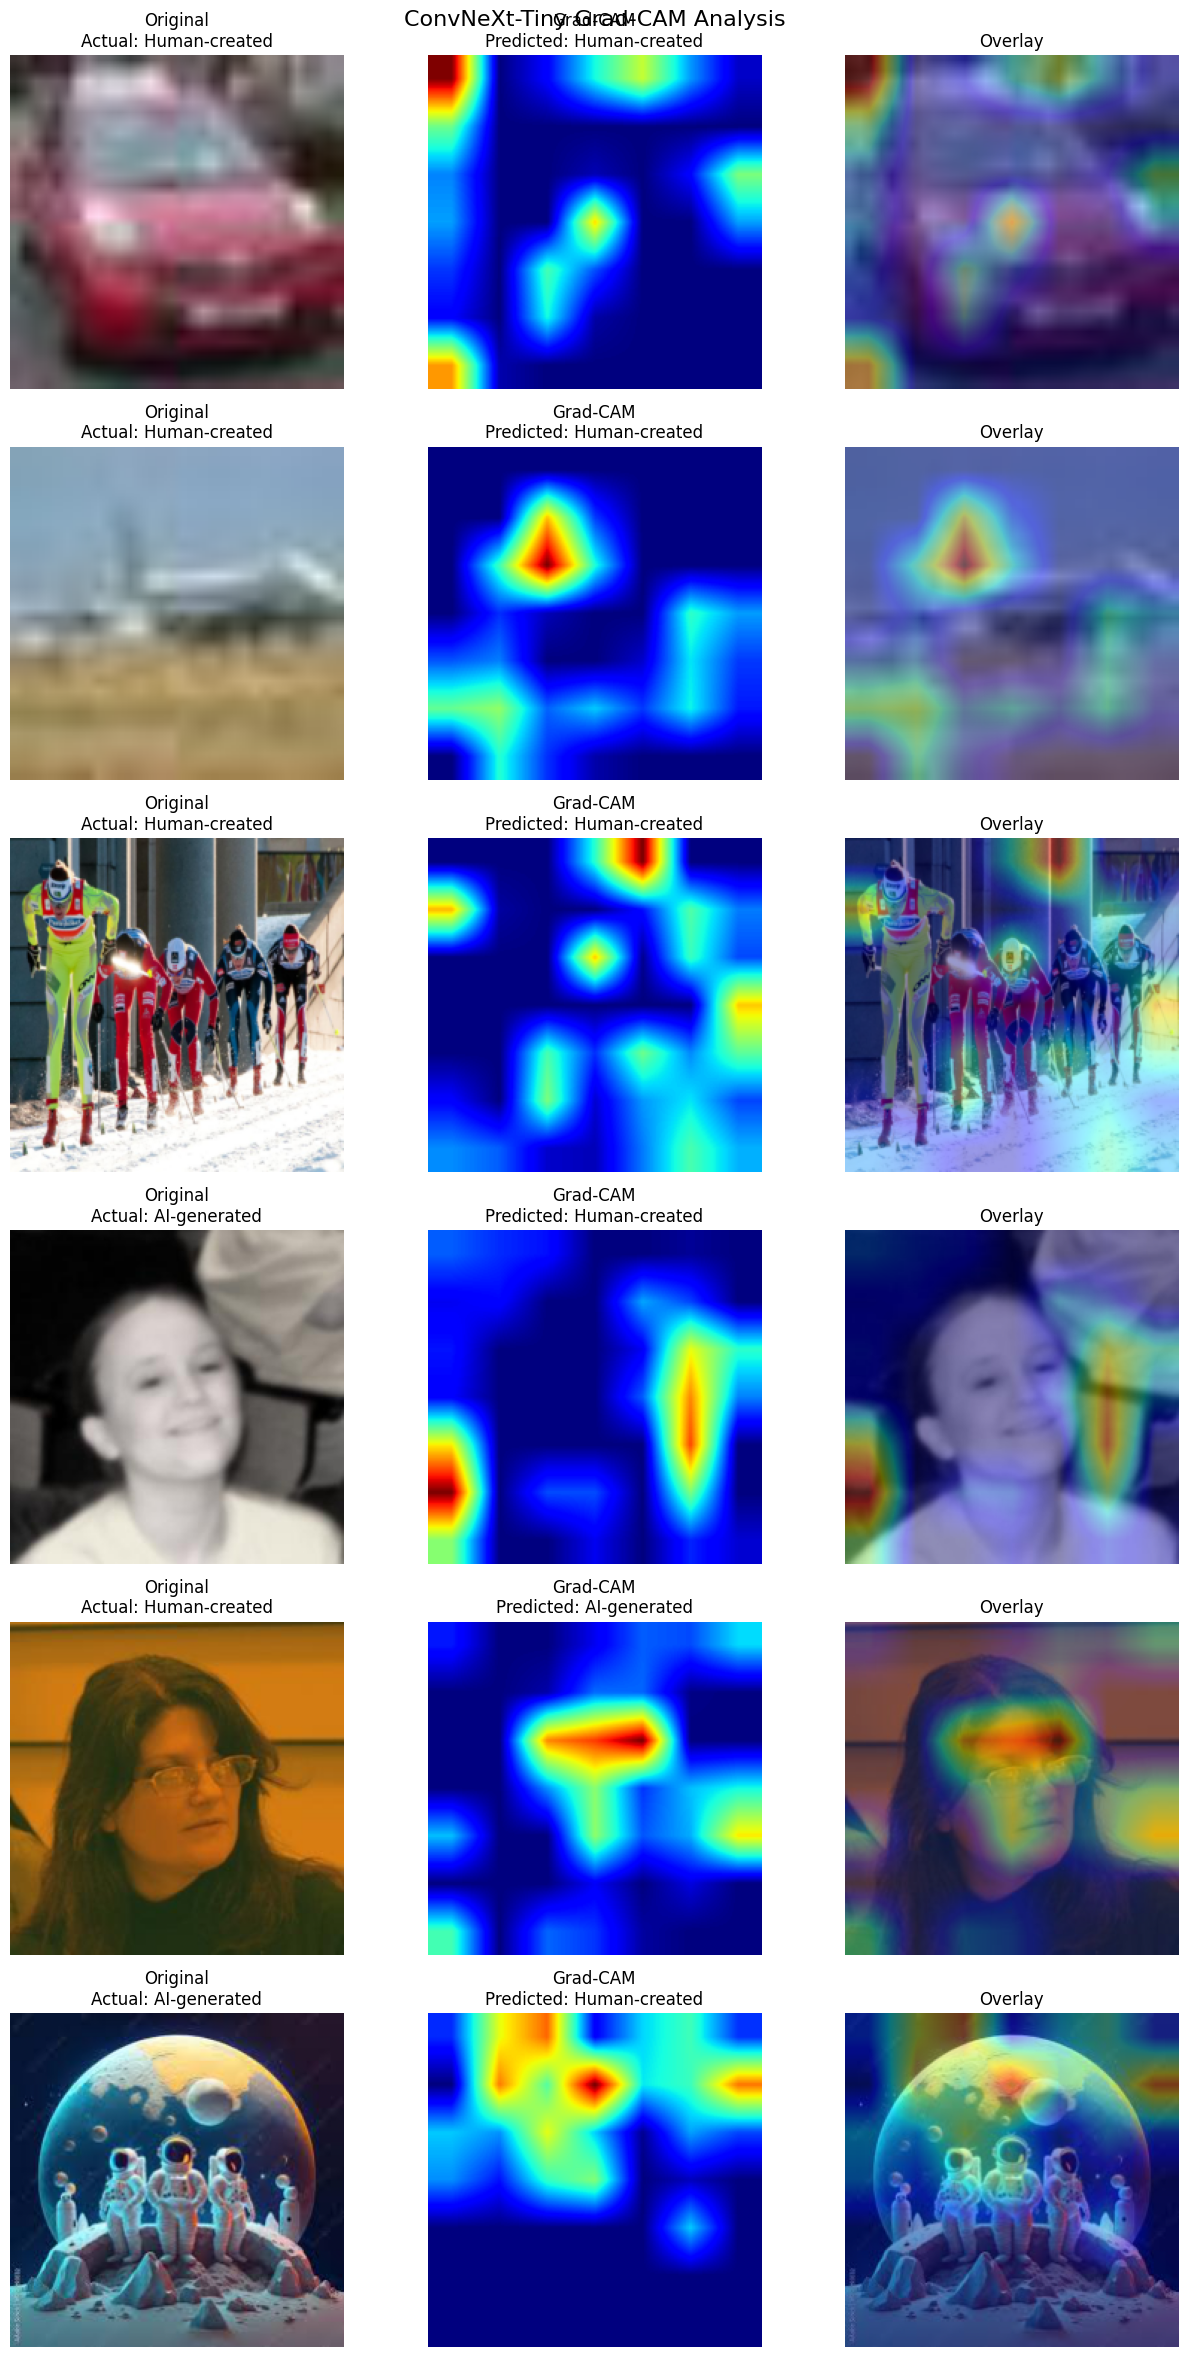

In [ ]:
# Step 39B — Corrected Grad-CAM for ConvNeXt-Tiny


import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Use the existing trained ConvNeXt-Tiny model
convnext_model = models_to_compare["ConvNeXt-Tiny"].to(DEVICE)
convnext_model.eval()

# The final ConvNeXt feature stage outputs [B, C, H, W].
target_layer = convnext_model.features[-1]

def generate_gradcam(image_tensor):
    """
    Generate Grad-CAM for the model's predicted class.
    image_tensor shape: [1, 3, IMAGE_SIZE, IMAGE_SIZE]
    """
    convnext_model.eval()
    convnext_model.zero_grad(set_to_none=True)

    cache = {}

    def forward_hook(module, inputs, output):
        cache["activations"] = output
        output.register_hook(
            lambda gradient: cache.__setitem__("gradients", gradient)
        )

    # Register temporarily so repeated calls don't accumulate hooks
    handle = target_layer.register_forward_hook(forward_hook)

    try:
        with torch.enable_grad():
            inputs = image_tensor.to(DEVICE)
            logits = convnext_model(inputs)

            predicted_class = int(logits.argmax(dim=1).item())
            score = logits[0, predicted_class]
            score.backward()

            activations = cache["activations"]
            gradients = cache["gradients"]

            # Torchvision ConvNeXt's final feature stage should be NCHW.
            if activations.ndim != 4 or gradients.ndim != 4:
                raise RuntimeError(
                    f"Expected 4D feature maps; got "
                    f"{tuple(activations.shape)} and "
                    f"{tuple(gradients.shape)}"
                )

            # Grad-CAM: average gradients spatially to get channel weights
            weights = gradients.mean(dim=(2, 3), keepdim=True)
            cam = F.relu((weights * activations).sum(dim=1, keepdim=True))

            cam = F.interpolate(
                cam,
                size=(IMAGE_SIZE, IMAGE_SIZE),
                mode="bilinear",
                align_corners=False
            )[0, 0]

            cam = cam - cam.min()
            cam = cam / cam.max().clamp_min(1e-8)

            return cam.detach().cpu().numpy(), predicted_class

    finally:
        handle.remove()


# Select three correctly classified and three misclassified test images
results = final_test_results["ConvNeXt-Tiny"]
y_true = np.asarray(results["labels"])
y_pred = np.asarray(results["predictions"])

wrong_indices = np.flatnonzero(y_true != y_pred)
correct_indices = np.flatnonzero(y_true == y_pred)

rng = np.random.default_rng(SEED)
selected_correct = rng.choice(
    correct_indices, size=min(3, len(correct_indices)), replace=False
)
selected_wrong = rng.choice(
    wrong_indices, size=min(3, len(wrong_indices)), replace=False
)

selected_indices = list(selected_correct) + list(selected_wrong)

fig, axes = plt.subplots(
    len(selected_indices), 3,
    figsize=(13, 4 * len(selected_indices)),
    squeeze=False
)

for row, idx in enumerate(selected_indices):
    idx = int(idx)
    original = dataset["test"][idx]["image"].convert("RGB")
    input_tensor = eval_transform(original).unsqueeze(0)

    heatmap, predicted_class = generate_gradcam(input_tensor)

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"Original\nActual: {LABEL_NAMES[int(y_true[idx])]}"
    )

    axes[row, 1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[row, 1].set_title(
        f"Grad-CAM\nPredicted: {LABEL_NAMES[predicted_class]}"
    )

    axes[row, 2].imshow(original)
    axes[row, 2].imshow(
        heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1
    )
    axes[row, 2].set_title("Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle("ConvNeXt-Tiny Grad-CAM Analysis", fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:
import os

project_dir = "/content/ai_image_detection"

print("Project directory exists:", os.path.isdir(project_dir))

if os.path.isdir(project_dir):
    for root, dirs, files in os.walk(project_dir):
        for filename in files:
            path = os.path.join(root, filename)
            print(f"{filename} — {os.path.getsize(path) / (1024**2):.2f} MB")
else:
    print("No project folder found yet.")

Project directory exists: True
convnext_tiny_ads504.pth — 106.20 MB
efficientnet_b0_ads504.pth — 15.59 MB
resnet50_ads504.pth — 90.00 MB


In [ ]:
import os
import json
import pandas as pd

project_dir = "/content/ai_image_detection"
os.makedirs(project_dir, exist_ok=True)

# Consolidate the final held-out test results
test_rows = []

for model_name, result in final_test_results.items():
    test_rows.append({
        "model": model_name,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "macro_f1": result["macro_f1"],
        "roc_auc": result["roc_auc"],
    })

test_df = pd.DataFrame(test_rows).sort_values(
    "accuracy", ascending=False
)

display(test_df.round(4))

test_path = os.path.join(project_dir, "test_metrics.csv")
test_df.to_csv(test_path, index=False)

# Save the image-quality robustness results
robustness_df = pd.DataFrame([
    {
        "condition": "Original",
        "accuracy": 0.8587,
        "balanced_accuracy": 0.8585,
        "roc_auc": 0.9317,
    },
    {
        "condition": "JPEG quality 75",
        "accuracy": 0.8060,
        "balanced_accuracy": 0.8055,
        "roc_auc": 0.8912,
    },
    {
        "condition": "JPEG quality 50",
        "accuracy": 0.7853,
        "balanced_accuracy": 0.7848,
        "roc_auc": 0.8751,
    },
    {
        "condition": "Downscaled to 56x56, then resized",
        "accuracy": 0.6980,
        "balanced_accuracy": 0.6965,
        "roc_auc": 0.8123,
    },
])

robustness_path = os.path.join(project_dir, "robustness_metrics.csv")
robustness_df.to_csv(robustness_path, index=False)

print("\nSaved:")
print(test_path)
print(robustness_path)

,model,accuracy,balanced_accuracy,macro_f1,roc_auc
2,ConvNeXt-Tiny,0.8587,0.8585,0.8585,0.9317
1,ResNet-50,0.8493,0.8495,0.8493,0.9323
0,EfficientNet-B0,0.8247,0.8249,0.8246,0.9104



Saved:
/content/ai_image_detection/test_metrics.csv
/content/ai_image_detection/robustness_metrics.csv


In [ ]:

import os
import json
import zipfile
from datetime import datetime

project_dir = "/content/ai_image_detection"
os.makedirs(project_dir, exist_ok=True)

# 1. Record experiment configuration and results
summary = {
    "project": "Generalizable AI-Generated Image Detection",
    "dataset": "tkbarb10/ADS504-Image-Arrays",
    "image_size": 224,
    "batch_size": 32,
    "seed": 42,
    "class_mapping": {
        "0": "AI-generated",
        "1": "Human-created"
    },
    "models": {
        "EfficientNet-B0": {
            "test_accuracy": 0.8247,
            "balanced_accuracy": 0.8249,
            "macro_f1": 0.8246,
            "roc_auc": 0.9104
        },
        "ResNet-50": {
            "test_accuracy": 0.8493,
            "balanced_accuracy": 0.8495,
            "macro_f1": 0.8493,
            "roc_auc": 0.9323
        },
        "ConvNeXt-Tiny": {
            "test_accuracy": 0.8587,
            "balanced_accuracy": 0.8585,
            "macro_f1": 0.8585,
            "roc_auc": 0.9317
        }
    },
    "robustness": {
        "Original": {"accuracy": 0.8587, "roc_auc": 0.9317},
        "JPEG quality 75": {"accuracy": 0.8060, "roc_auc": 0.8912},
        "JPEG quality 50": {"accuracy": 0.7853, "roc_auc": 0.8751},
        "Downscaled 56x56 then resized": {
            "accuracy": 0.6980,
            "roc_auc": 0.8123
        }
    },
    "limitations": [
        "Unseen-generator generalization has not been validated.",
        "The dataset does not provide sufficient per-image generator provenance.",
        "Robustness results apply to the tested transformations only.",
        "Grad-CAM visualizations are qualitative and do not prove causal reasoning."
    ]
}

summary_path = os.path.join(project_dir, "experiment_summary.json")
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

# 2. Create the final report
report = """# Generalizable AI-Generated Image Detection

## 1. Objective
Develop and compare deep-learning classifiers for distinguishing
AI-generated images from human-created images, with particular
attention to model comparison and image-quality robustness.

## 2. Dataset
Dataset: tkbarb10/ADS504-Image-Arrays
- Training images: 11,998
- Validation images: 1,499
- Test images: 1,500
- Image size: 224 x 224
- Class 0: AI-generated
- Class 1: Human-created

The dataset includes images associated with multiple source collections,
but per-image generator provenance is unavailable in the loaded dataset.
Consequently, the split does not establish generalization to unseen generators.

## 3. Models and training
The following pretrained architectures were evaluated:
- EfficientNet-B0
- ResNet-50
- ConvNeXt-Tiny

The experiment used a shared preprocessing pipeline, ImageNet
normalization, a batch size of 32, and a fixed random seed of 42.
Training included classifier-head training and fine-tuning selected
later backbone layers. Validation loss was used for checkpoint selection.

## 4. Held-out test results

| Model | Accuracy | Balanced accuracy | Macro F1 | ROC-AUC |
|---|---:|---:|---:|---:|
| EfficientNet-B0 | 82.47% | 82.49% | 82.46% | 91.04% |
| ResNet-50 | 84.93% | 84.95% | 84.93% | 93.23% |
| ConvNeXt-Tiny | 85.87% | 85.85% | 85.85% | 93.17% |

ConvNeXt-Tiny achieved the highest test accuracy and macro F1.
ResNet-50 achieved a marginally higher ROC-AUC. The small AUC difference
should not be interpreted as evidence of a meaningful statistical advantage.

## 5. Image-quality robustness
The ConvNeXt-Tiny model was evaluated on the original test images and
versions transformed using JPEG compression or downscaling.

| Condition | Accuracy | ROC-AUC |
|---|---:|---:|
| Original | 85.87% | 93.17% |
| JPEG quality 75 | 80.60% | 89.12% |
| JPEG quality 50 | 78.53% | 87.51% |
| Downscale to 56x56, then resize | 69.80% | 81.23% |

Performance declined under the tested image-quality transformations,
especially downscaling. These results indicate sensitivity to the
specific transformations evaluated; they do not establish performance
under every real-world image degradation.

## 6. Error analysis
The held-out test evaluation produced 212 errors among 1,500 images,
corresponding to a 14.13% error rate for ConvNeXt-Tiny.

Confusion matrix:
- AI-generated correctly classified: 669
- AI-generated classified as human-created: 86
- Human-created classified as AI-generated: 126
- Human-created correctly classified: 619

The sample of visually inspected mistakes included portraits, artwork,
objects, and other scenes. These examples motivate further investigation
but do not establish the cause of model errors.

## 7. Interpretability
Grad-CAM was applied to selected correctly classified and misclassified
examples using the final ConvNeXt feature stage. Heatmaps varied across
images and sometimes highlighted regions outside the main subject.
These visualizations are qualitative: they do not prove causal reasoning
or identify a definitive explanation for each prediction.

## 8. Limitations
1. Generalization to genuinely unseen image generators has not been
   validated using an independent, provenance-verified external dataset.
2. Dataset source overlap and collection biases may influence performance.
3. Only the specified JPEG and downscaling transformations were tested.
4. Grad-CAM provides approximate visual explanations.
5. No confidence intervals or statistical significance tests were performed.

## 9. Conclusion
ConvNeXt-Tiny was the strongest model by test accuracy and macro F1 on
ADS504, while ResNet-50 achieved a slightly higher ROC-AUC. Image-quality
experiments revealed substantial performance degradation under compression
and especially downscaling. The results support performance on this dataset
and under the tested transformations, but do not yet demonstrate
generalization to unseen generators.

## 10. Reproducibility
Model checkpoints, test metrics, robustness metrics, and experiment
configuration are included in the accompanying project package.
"""

report_path = os.path.join(project_dir, "final_project_report.md")
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

# 3. Verify expected checkpoints and package all artifacts
checkpoint_names = [
    "efficientnet_b0_ads504.pth",
    "resnet50_ads504.pth",
    "convnext_tiny_ads504.pth"
]

missing = [
    name for name in checkpoint_names
    if not os.path.isfile(os.path.join(project_dir, name))
]
if missing:
    raise FileNotFoundError(f"Missing model checkpoints: {missing}")

zip_path = "/content/ai_image_detection_project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in os.listdir(project_dir):
        path = os.path.join(project_dir, filename)
        if os.path.isfile(path):
            archive.write(path, arcname=f"ai_image_detection/{filename}")

print("Project report:", report_path)
print("Experiment summary:", summary_path)
print("Project package:", zip_path)
print("Package size: {:.1f} MB".format(os.path.getsize(zip_path) / (1024**2)))
print("Checkpoints verified:", len(checkpoint_names))


Project report: /content/ai_image_detection/final_project_report.md
Experiment summary: /content/ai_image_detection/experiment_summary.json
Project package: /content/ai_image_detection_project.zip
Package size: 196.5 MB
Checkpoints verified: 3


In [ ]:
from google.colab import files
files.download("/content/ai_image_detection_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>